<a href="https://colab.research.google.com/github/viba2001/AI_Science_Engineering_Fall26/blob/main/Tutorial_3_PINNS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PINN for solving 1D heat equation

In [1]:
from google.colab import drive
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import time
torch.autograd.set_detect_anomaly(True)
torch.manual_seed(128)

Epoch 0, Total Loss = 0.651980, PDE Loss = 0.001787, BC Loss = 0.056705, IC Loss = 0.593487
Epoch 500, Total Loss = 0.026970, PDE Loss = 0.010655, BC Loss = 0.005448, IC Loss = 0.010867
Epoch 1000, Total Loss = 0.002414, PDE Loss = 0.001757, BC Loss = 0.000289, IC Loss = 0.000368
Epoch 1500, Total Loss = 0.000830, PDE Loss = 0.000675, BC Loss = 0.000061, IC Loss = 0.000095
Epoch 2000, Total Loss = 0.000451, PDE Loss = 0.000373, BC Loss = 0.000026, IC Loss = 0.000052
Epoch 2500, Total Loss = 0.000297, PDE Loss = 0.000246, BC Loss = 0.000017, IC Loss = 0.000034
Epoch 3000, Total Loss = 0.000217, PDE Loss = 0.000181, BC Loss = 0.000012, IC Loss = 0.000024
Epoch 3500, Total Loss = 0.000192, PDE Loss = 0.000161, BC Loss = 0.000013, IC Loss = 0.000017
Epoch 4000, Total Loss = 0.000935, PDE Loss = 0.000714, BC Loss = 0.000204, IC Loss = 0.000017
Epoch 4500, Total Loss = 0.000113, PDE Loss = 0.000098, BC Loss = 0.000005, IC Loss = 0.000010

Relative L2 Error = 0.4602%


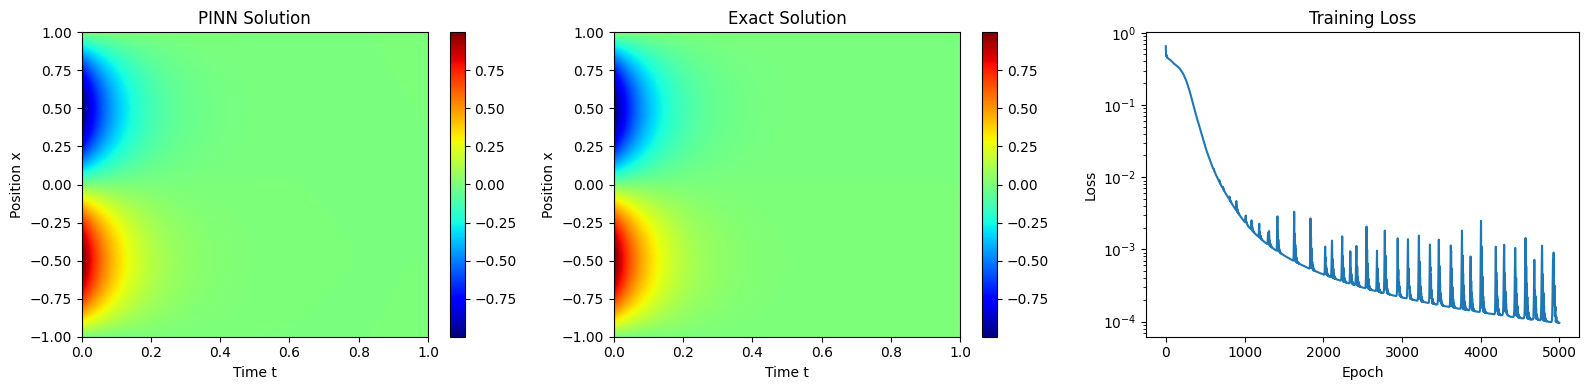

In [1]:

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)

# --------------------------------------------------
# 1. Define the problem

N_int = 2000       # Interior points
N_bc = 200         # Boundary points
N_ic = 200         # Initial condition points

# --------------------------------------------------
# 2. Generate training points

# Interior points: -1 < x < 1, 0 < t < 1
x_int = -1 + 2 * torch.rand(N_int, 1)
t_int = torch.rand(N_int, 1)

# Boundary points: x = -1 and x = 1
t_bc = torch.rand(N_bc, 1)

x_left = -torch.ones(N_bc, 1)
x_right = torch.ones(N_bc, 1)

# Initial condition: t = 0
x_ic = -1 + 2 * torch.rand(N_ic, 1)
t_ic = torch.zeros(N_ic, 1)

u_ic = -torch.sin(torch.pi * x_ic)

# --------------------------------------------------
# 3. Build the neural network

model = nn.Sequential(
    nn.Linear(2, 50),
    nn.Tanh(),
    nn.Linear(50, 50),
    nn.Tanh(),
    nn.Linear(50, 1)
)

# --------------------------------------------------
# 4. Set up the optimizer

optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5000
loss_history = []

# --------------------------------------------------
# 5. Train the PINN

for epoch in range(epochs):

    optimizer.zero_grad()

    # Combine interior coordinates
    xt = torch.cat((x_int, t_int), dim=1)
    xt.requires_grad_(True)

    # Predict u(x,t)
    u = model(xt)

    # First derivatives: du/dx and du/dt
    grad_u = torch.autograd.grad(
        u, xt,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_x = grad_u[:, 0:1]
    u_t = grad_u[:, 1:2]

    # Second derivative: d2u/dx2
    grad_u_x = torch.autograd.grad(
        u_x, xt,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0]

    u_xx = grad_u_x[:, 0:1]

    # PDE residual: ut - uxx = 0
    residual = u_t - u_xx
    loss_pde = torch.mean(residual**2)

    # Boundary condition: u(-1,t) = u(1,t) = 0
    u_left = model(torch.cat((x_left, t_bc), dim=1))
    u_right = model(torch.cat((x_right, t_bc), dim=1))

    loss_bc = torch.mean(u_left**2) + torch.mean(u_right**2)

    # Initial condition: u(x,0) = -sin(pi*x)
    u_initial = model(torch.cat((x_ic, t_ic), dim=1))
    loss_ic = torch.mean((u_initial - u_ic)**2)

    # Total loss
    loss = loss_pde + loss_bc + loss_ic

    # Backpropagation and weight update
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}, "
            f"Total Loss = {loss.item():.6f}, "
            f"PDE Loss = {loss_pde.item():.6f}, "
            f"BC Loss = {loss_bc.item():.6f}, "
            f"IC Loss = {loss_ic.item():.6f}"
        )

# --------------------------------------------------
# 6. Test against the exact solution

x_test = torch.linspace(-1, 1, 150).reshape(-1, 1)
t_test = torch.linspace(0, 1, 150).reshape(-1, 1)

X, T = torch.meshgrid(
    x_test.squeeze(),
    t_test.squeeze(),
    indexing="ij"
)

test_points = torch.cat(
    (X.reshape(-1, 1), T.reshape(-1, 1)),
    dim=1
)

with torch.no_grad():
    u_pred = model(test_points).reshape(150, 150)

    u_exact = (
        -torch.exp(-torch.pi**2 * T)
        * torch.sin(torch.pi * X)
    )

# Relative L2 error in percent
relative_error = (
    torch.linalg.norm(u_pred - u_exact)
    / torch.linalg.norm(u_exact)
) * 100

print(f"\nRelative L2 Error = {relative_error.item():.4f}%")

# --------------------------------------------------
# 7. Plot the results
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# PINN solution
im1 = axes[0].imshow(
    u_pred.detach().numpy(),
    extent=[0, 1, -1, 1],
    origin="lower",
    aspect="auto",
    cmap="jet"
)
axes[0].set_title("PINN Solution")
axes[0].set_xlabel("Time t")
axes[0].set_ylabel("Position x")
plt.colorbar(im1, ax=axes[0])

# Exact solution
im2 = axes[1].imshow(
    u_exact.numpy(),
    extent=[0, 1, -1, 1],
    origin="lower",
    aspect="auto",
    cmap="jet"
)
axes[1].set_title("Exact Solution")
axes[1].set_xlabel("Time t")
axes[1].set_ylabel("Position x")
plt.colorbar(im2, ax=axes[1])

# Training loss
axes[2].plot(loss_history)
axes[2].set_yscale("log")
axes[2].set_title("Training Loss")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")

plt.tight_layout()
plt.show()


# PINNS for solving 1D Wave equation

Epoch 0, Total Loss = 0.648127, PDE Loss = 0.001795, BC Loss = 0.025650, IC Loss = 0.620681
Epoch 500, Total Loss = 0.306850, PDE Loss = 0.001567, BC Loss = 0.075724, IC Loss = 0.229560
Epoch 1000, Total Loss = 0.253242, PDE Loss = 0.002226, BC Loss = 0.069666, IC Loss = 0.181350
Epoch 1500, Total Loss = 0.166002, PDE Loss = 0.003512, BC Loss = 0.062865, IC Loss = 0.099625
Epoch 2000, Total Loss = 0.093786, PDE Loss = 0.004560, BC Loss = 0.048280, IC Loss = 0.040946
Epoch 2500, Total Loss = 0.042759, PDE Loss = 0.003175, BC Loss = 0.026370, IC Loss = 0.013215
Epoch 3000, Total Loss = 0.021088, PDE Loss = 0.001928, BC Loss = 0.013418, IC Loss = 0.005741
Epoch 3500, Total Loss = 0.010759, PDE Loss = 0.001415, BC Loss = 0.006500, IC Loss = 0.002844
Epoch 4000, Total Loss = 0.004415, PDE Loss = 0.000965, BC Loss = 0.002440, IC Loss = 0.001009
Epoch 4500, Total Loss = 0.001558, PDE Loss = 0.000486, BC Loss = 0.000846, IC Loss = 0.000226

Relative L2 Error = 2.1931%


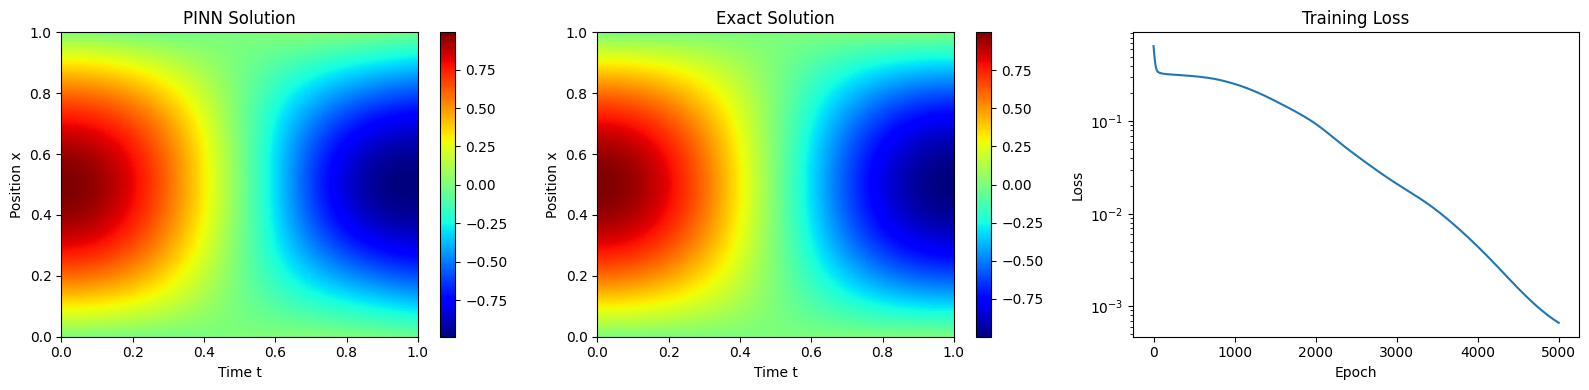

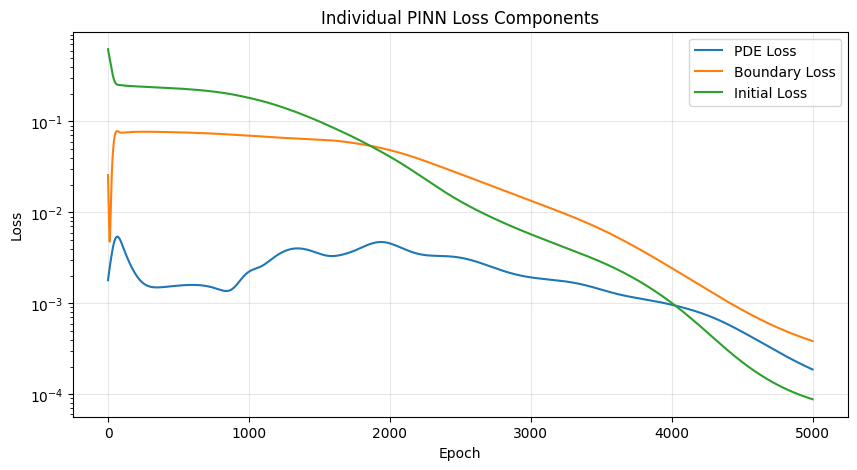

In [9]:
# Necessary imports

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)

# Define total number of data points
N_interior = 2000
N_boundary = 200
N_initial  = 200

# Create these data points
x_int = torch.rand(N_interior).reshape(-1, 1)
t_int = torch.rand(N_interior).reshape(-1, 1)
xt_interior = torch.cat((x_int, t_int),dim = 1)
xt_interior.requires_grad_(True)

x_left_bc  = torch.zeros(N_boundary).reshape(-1, 1)
x_right_bc = torch.ones(N_boundary).reshape(-1, 1)
t_bc       = torch.rand(N_boundary).reshape(-1, 1)
xt_leftBC  = torch.cat((x_left_bc, t_bc),dim = 1)
xt_rightBC = torch.cat((x_right_bc, t_bc),dim = 1)
xt_leftBC.requires_grad_(True)
xt_rightBC.requires_grad_(True)

x_initial  = torch.rand(N_initial).reshape(-1, 1)
t_initial  = torch.zeros(N_initial).reshape(-1, 1)
xt_initial = torch.cat((x_initial, t_initial), dim = 1)
xt_initial.requires_grad_(True)

# Build the neural network
model = nn.Sequential(
    nn.Linear(2, 50),
    nn.Tanh(),
    nn.Linear(50, 50),
    nn.Tanh(),
    nn.Linear(50, 1)
)

# Set up the optimizer
optimizer = optim.Adam(model.parameters(), lr=0.0001)

epochs = 5000
loss_history = []
pde_history = []
bc_history = []
ic_history = []

#-------------------------------------------------------------------------------
# Train the PINN
for epoch in range(epochs):
    optimizer.zero_grad()

    # Predict internal values with current neural network
    u = model(xt_interior)

    # First derivatives: du/dx and du/dt
    grad_u = torch.autograd.grad(u, xt_interior, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grad_u[:, 0:1]
    u_t = grad_u[:, 1:2]

    # Second derivative: d2u/dx2
    grad_u_x = torch.autograd.grad(u_x, xt_interior, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    u_xx = grad_u_x[:, 0:1]

    grad_u_t = torch.autograd.grad(u_t, xt_interior, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    u_tt = grad_u_t[:, 1:2]

    # PDE residual: utt - uxx = 0
    residual = u_tt - u_xx
    loss_pde = torch.mean(residual**2)

    #---------------------------------------------------------------------------

    # Predict the boundary values with current neural network
    u_left  = model(xt_leftBC)
    u_right = model(xt_rightBC)

    # Boundary residuals
    r_leftBC = u_left - 0
    r_rightBC = u_right - 0
    loss_boundary = torch.mean(r_leftBC**2) + torch.mean(r_rightBC**2)

    #---------------------------------------------------------------------------

    # Predict the initial position values with current neural netowork
    u_initial_position = model(xt_initial)

    # First time gradient for valocity
    grad_u = torch.autograd.grad(u_initial_position, xt_initial, grad_outputs=torch.ones_like(u_initial_position), create_graph=True)[0]
    u_initial_velocity = grad_u[:, 1:2]

    # Residuals
    r_position = u_initial_position - torch.sin(torch.pi * x_initial)
    r_velocity = u_initial_velocity - 0
    loss_initial = torch.mean(r_position**2) + torch.mean(r_velocity**2)

    #---------------------------------------------------------------------------

    # Total loss
    loss = loss_pde + loss_boundary + loss_initial

    # Backpropagation and weight update
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())
    pde_history.append(loss_pde.item())
    bc_history.append(loss_boundary.item())
    ic_history.append(loss_initial.item())

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}, "
            f"Total Loss = {loss.item():.6f}, "
            f"PDE Loss = {loss_pde.item():.6f}, "
            f"BC Loss = {loss_boundary.item():.6f}, "
            f"IC Loss = {loss_initial.item():.6f}"
        )

#-------------------------------------------------------------------------------
# Compare against exact solution

x_test = torch.linspace(0, 1, 200).reshape(-1, 1)
t_test = torch.linspace(0, 1, 200).reshape(-1, 1)

X, T = torch.meshgrid(x_test.squeeze(),t_test.squeeze(),indexing="ij")

test_points = torch.cat((X.reshape(-1, 1), T.reshape(-1, 1)),dim=1)

with torch.no_grad():
    u_pred = model(test_points).reshape(200, 200)
    u_exact = (torch.sin(torch.pi*X) * torch.cos(torch.pi * T))

# Relative L2 error in percent
relative_error = (torch.linalg.norm(u_pred - u_exact)/ torch.linalg.norm(u_exact)) * 100

print(f"\nRelative L2 Error = {relative_error.item():.4f}%")

#-------------------------------------------------------------------------------
# Plots

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# PINN solution
im1 = axes[0].imshow(u_pred.detach().numpy(),extent=[0, 1, 0, 1],
    origin="lower",aspect="auto", cmap="jet")
axes[0].set_title("PINN Solution")
axes[0].set_xlabel("Time t")
axes[0].set_ylabel("Position x")
plt.colorbar(im1, ax=axes[0])

# Exact solution
im2 = axes[1].imshow(
    u_exact.numpy(),
    extent=[0, 1, 0, 1],
    origin="lower",
    aspect="auto",
    cmap="jet"
)
axes[1].set_title("Exact Solution")
axes[1].set_xlabel("Time t")
axes[1].set_ylabel("Position x")
plt.colorbar(im2, ax=axes[1])

# Training loss
axes[2].plot(loss_history)
axes[2].set_yscale("log")
axes[2].set_title("Training Loss")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(pde_history, label="PDE Loss")
plt.plot(bc_history, label="Boundary Loss")
plt.plot(ic_history, label="Initial Loss")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Individual PINN Loss Components")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()




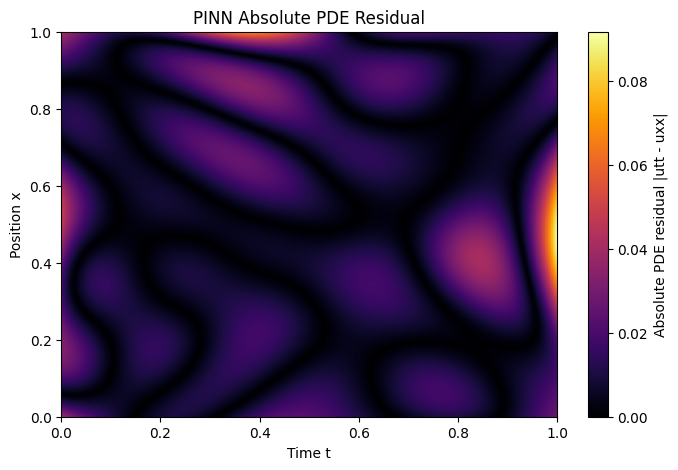

Maximum absolute residual: 0.09163665771484375
Mean absolute residual: 0.010625813156366348


In [10]:
# Create a dense grid
x_res = torch.linspace(0, 1, 200).reshape(-1, 1)
t_res = torch.linspace(0, 1, 200).reshape(-1, 1)

X_res, T_res = torch.meshgrid(
    x_res.squeeze(),
    t_res.squeeze(),
    indexing="ij"
)

# Combine x and t into model inputs
xt_res = torch.cat(
    (X_res.reshape(-1, 1), T_res.reshape(-1, 1)),
    dim=1
).requires_grad_(True)

# Predict u(x,t)
u_res = model(xt_res)

# First derivatives
grad_u = torch.autograd.grad(
    u_res, xt_res,
    grad_outputs=torch.ones_like(u_res),
    create_graph=True
)[0]

u_x = grad_u[:, 0:1]
u_t = grad_u[:, 1:2]

# Second derivatives
grad_u_x = torch.autograd.grad(
    u_x, xt_res,
    grad_outputs=torch.ones_like(u_x),
    create_graph=True
)[0]

grad_u_t = torch.autograd.grad(
    u_t, xt_res,
    grad_outputs=torch.ones_like(u_t),
    create_graph=True
)[0]

u_xx = grad_u_x[:, 0:1]
u_tt = grad_u_t[:, 1:2]

# Calculate absolute PDE residual
residual = u_tt - u_xx
abs_residual = residual.abs().detach().reshape(200, 200)

# Plot residual heatmap
plt.figure(figsize=(8, 5))
plt.imshow(
    abs_residual.numpy(),
    extent=[0, 1, 0, 1],
    origin="lower",
    aspect="auto",
    cmap="inferno"
)
plt.colorbar(label="Absolute PDE residual |utt - uxx|")
plt.xlabel("Time t")
plt.ylabel("Position x")
plt.title("PINN Absolute PDE Residual")
plt.show()

print("Maximum absolute residual:", abs_residual.max().item())
print("Mean absolute residual:", abs_residual.mean().item())

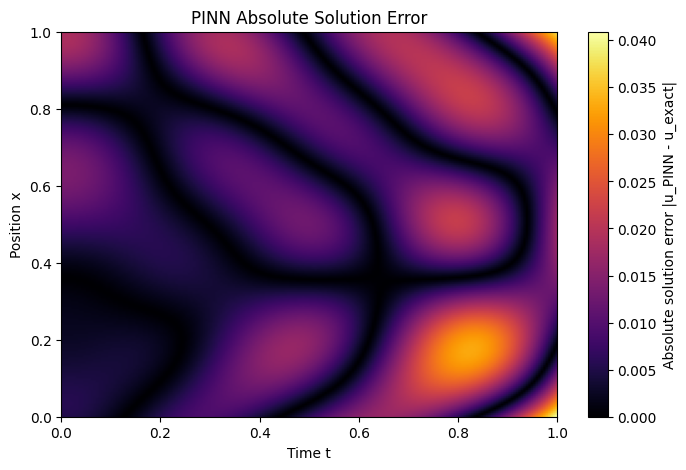

Maximum absolute error: 0.040900468826293945
Mean absolute error: 0.008699368685483932


In [11]:
# ---------------------------------------------------------
# Absolute solution error: |u_PINN - u_exact|
# ---------------------------------------------------------

# Predict solution on the dense grid
with torch.no_grad():
    u_pred_grid = model(
        torch.cat(
            (X_res.reshape(-1, 1), T_res.reshape(-1, 1)),
            dim=1
        )
    ).reshape(200, 200)

    # Analytical solution for the wave equation
    u_exact_grid = torch.sin(torch.pi * X_res) * torch.cos(torch.pi * T_res)

# Calculate absolute error
abs_error = torch.abs(u_pred_grid - u_exact_grid)

# Plot error heatmap
plt.figure(figsize=(8, 5))

plt.imshow(
    abs_error.numpy(),
    extent=[0, 1, 0, 1],
    origin="lower",
    aspect="auto",
    cmap="inferno"
)

plt.colorbar(label="Absolute solution error |u_PINN - u_exact|")
plt.xlabel("Time t")
plt.ylabel("Position x")
plt.title("PINN Absolute Solution Error")
plt.show()

# Error statistics
print("Maximum absolute error:", abs_error.max().item())
print("Mean absolute error:", abs_error.mean().item())

In [12]:
# Boundary-condition errors
with torch.no_grad():
    u_left_test = model(
        torch.cat((torch.zeros_like(t_test), t_test), dim=1)
    )
    u_right_test = model(
        torch.cat((torch.ones_like(t_test), t_test), dim=1)
    )

    # Initial displacement error
    u_initial_test = model(
        torch.cat((x_test, torch.zeros_like(x_test)), dim=1)
    )
    u_initial_exact = torch.sin(torch.pi * x_test)

print("Max left BC error:",
      u_left_test.abs().max().item())

print("Max right BC error:",
      u_right_test.abs().max().item())

print("Max initial displacement error:",
      (u_initial_test - u_initial_exact).abs().max().item())

Max left BC error: 0.04090052843093872
Max right BC error: 0.03713765740394592
Max initial displacement error: 0.01864418387413025
